# Análisis de entrenamiento de BTC/USDT

Este cuaderno usa solo entrenamiento para explorar y justificar el estado. No muestra el periodo final. La instantánea del CSV y sus metadatos están incluidos.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
assert (root / "configs/default.json").exists(), "Abre el cuaderno desde el proyecto"
os.chdir(root)
sys.path.insert(0, str(root))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/rl_inversion_matplotlib")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import prepare, FEATURES
cfg = json.loads(Path("configs/default.json").read_text())
df, x, splits, mu, sigma = prepare(cfg["data"], cfg)
train = df.iloc[:splits["train"][1]+1].copy()
print("EDA restringido a entrenamiento:", train.timestamp.iloc[0], "a", train.timestamp.iloc[-1])

EDA restringido a entrenamiento: 2020-01-21 00:00:00+00:00 a 2023-01-08 00:00:00+00:00


## Calidad y descripción

Revisar orden, duplicados y frecuencia evita simular recorridos imposibles. El timestamp etiqueta la vela diaria UTC; su cierre se conoce al terminar el día.

In [2]:
assert train.timestamp.is_monotonic_increasing
assert not train.timestamp.duplicated().any()
assert (train.close > 0).all()
display(train[["close", "volume"] + FEATURES].describe())
print("Saltos de fechas:", train.timestamp.diff().value_counts().to_dict())

,close,volume,return_1,momentum_5,momentum_20,gap_sma20,volatility_20
count,1084.000000,1084.000000,1084.000000,1084.000000,1084.000000,1084.000000,1084.000000
mean,29176.842232,96610.487643,0.001403,0.006616,0.030110,0.008313,0.034692
std,16991.469742,85419.506959,0.038651,0.083291,0.187163,0.097336,0.014880
min,4800.000000,15805.447180,-0.395048,-0.459865,-0.503981,-0.441886,0.008225
25%,11919.227500,46204.369425,-0.015546,-0.036926,-0.084290,-0.044372,0.026564
50%,23848.835000,65828.662486,0.001102,0.006723,0.010394,0.004387,0.032566
75%,43074.322500,111882.503306,0.018521,0.052056,0.116932,0.059696,0.040013
max,67525.830000,760705.362783,0.195361,0.256757,0.712341,0.390491,0.111594


Saltos de fechas: {Timedelta('1 days 00:00:00'): 1083}


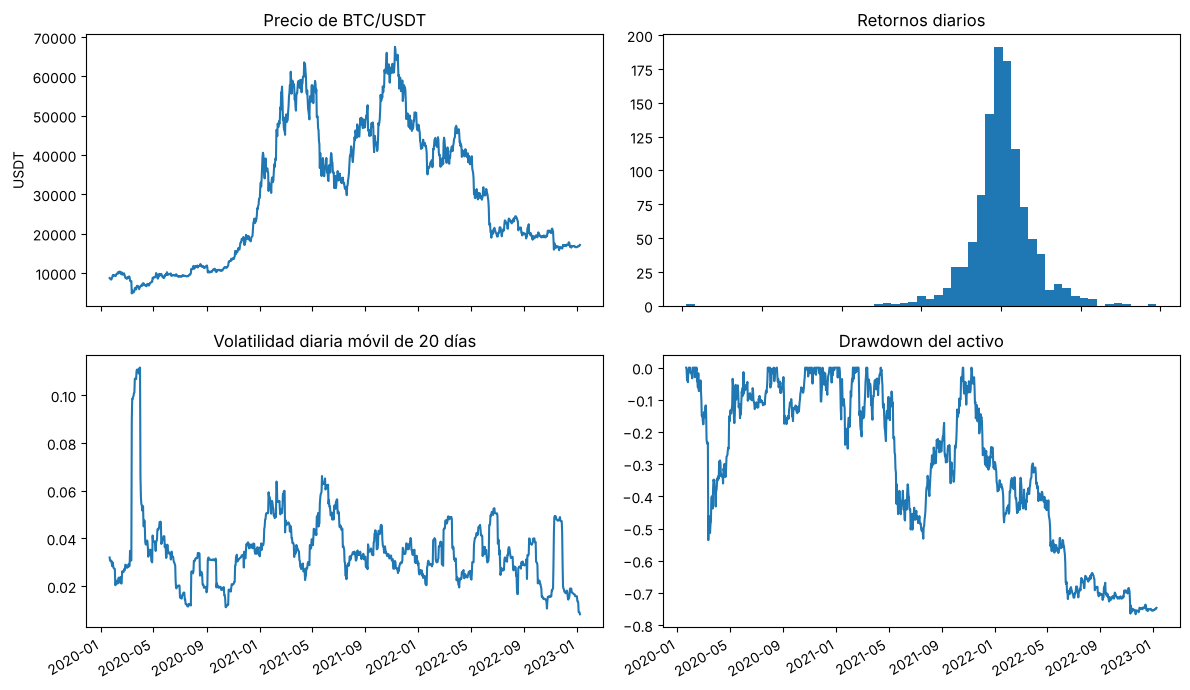

Mayor caída diaria: -0.3950484717412017
Mayor subida diaria: 0.1953613919484356
Drawdown máximo del precio en entrenamiento: -0.7662925431645935


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(train.timestamp, train.close)
ax[0, 0].set(title="Precio de BTC/USDT", ylabel="USDT")
ax[0, 1].hist(train.return_1, bins=55)
ax[0, 1].set(title="Retornos diarios", xlabel="Retorno")
ax[1, 0].plot(train.timestamp, train.volatility_20)
ax[1, 0].set(title="Volatilidad diaria móvil de 20 días")
asset_dd = train.close / train.close.cummax() - 1
ax[1, 1].plot(train.timestamp, asset_dd)
ax[1, 1].set(title="Drawdown del activo")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print("Mayor caída diaria:", train.return_1.min())
print("Mayor subida diaria:", train.return_1.max())
print("Drawdown máximo del precio en entrenamiento:", asset_dd.min())

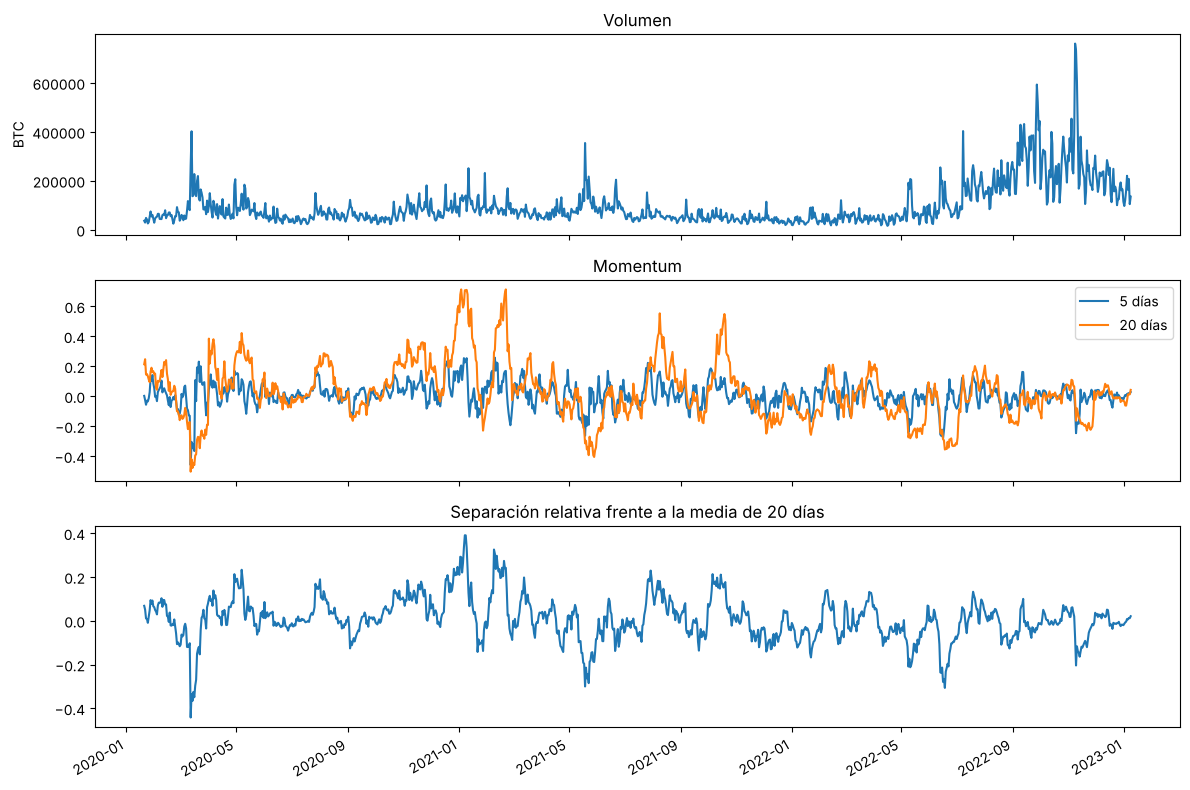

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(train.timestamp, train.volume)
axes[0].set(ylabel="BTC", title="Volumen")
axes[1].plot(train.timestamp, train.momentum_5, label="5 días")
axes[1].plot(train.timestamp, train.momentum_20, label="20 días")
axes[1].legend()
axes[1].set(title="Momentum")
axes[2].plot(train.timestamp, train.gap_sma20)
axes[2].set(title="Separación relativa frente a la media de 20 días")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [5]:
high = train.nlargest(5, "volatility_20")[["timestamp", "volatility_20", "return_1"]]
low = train.nsmallest(5, "volatility_20")[["timestamp", "volatility_20", "return_1"]]
display(high)
display(low)
display(train[FEATURES].corr())

,timestamp,volatility_20,return_1
69,2020-03-30 00:00:00+00:00,0.111594,0.087217
70,2020-03-31 00:00:00+00:00,0.111586,0.002512
66,2020-03-27 00:00:00+00:00,0.110847,-0.056142
63,2020-03-24 00:00:00+00:00,0.110790,0.042894
65,2020-03-26 00:00:00+00:00,0.110409,0.008975


,timestamp,volatility_20,return_1
1083,2023-01-08 00:00:00+00:00,0.008225,0.010875
1082,2023-01-07 00:00:00+00:00,0.009037,-0.000418
1081,2023-01-06 00:00:00+00:00,0.009057,0.007058
1080,2023-01-05 00:00:00+00:00,0.009122,-0.001098
1007,2022-10-24 00:00:00+00:00,0.010608,-0.012298


,return_1,momentum_5,momentum_20,gap_sma20,volatility_20
return_1,1.000000,0.453523,0.217731,0.371787,0.005353
momentum_5,0.453523,1.000000,0.521495,0.760536,-0.056999
momentum_20,0.217731,0.521495,1.000000,0.867635,-0.202048
gap_sma20,0.371787,0.760536,0.867635,1.000000,-0.189147
volatility_20,0.005353,-0.056999,-0.202048,-0.189147,1.000000


## Calibración de la penalización por operar (v2)

La recompensa `turnover` resta `kappa × fracción negociada`. Para elegir `kappa` sin mirar validación ni prueba se compara contra el tamaño típico del movimiento diario **en entrenamiento**: un cambio completo de posición (0 % → 100 %) debería exigir que el agente espere un movimiento claramente mayor que el ruido de un día común, pero sin prohibir operar.

In [6]:
abs_r = train.return_1.abs()
kappa = json.loads(Path('configs/v2.json').read_text())['turnover_kappa']
print(f"|retorno diario| mediano: {abs_r.median():.2%}  medio: {abs_r.mean():.2%}")
print(f"Costo real de un cambio completo (0,10 %): {cfg['cost_rate']:.2%}")
print(f"Penalización adicional kappa={kappa}: {kappa:.2%} por cambio completo")
print(f"Ida y vuelta (0→100→0): costo {2*cfg['cost_rate']:.2%} + penalización {2*kappa:.2%} = {2*(cfg['cost_rate']+kappa):.2%}")
print(f"Fracción de días con |retorno| mayor que ese umbral: {(abs_r > 2*(cfg['cost_rate']+kappa)).mean():.1%}")

|retorno diario| mediano: 1.74%  medio: 2.60%
Costo real de un cambio completo (0,10 %): 0.10%
Penalización adicional kappa=0.005: 0.50% por cambio completo
Ida y vuelta (0→100→0): costo 0.20% + penalización 1.00% = 1.20%
Fracción de días con |retorno| mayor que ese umbral: 60.9%


## Interpretación

La caída diaria más grande y el drawdown del activo muestran por qué el retorno acumulado no basta para evaluar al agente. La variación de volatilidad justifica incluir una medida móvil en el estado. Los retornos de 5 y 20 días describen cambios de tendencia sin depender de la cotización absoluta. La correlación entre indicadores permite detectar redundancia, aunque en este experimento se conserva la representación fijada antes de prueba.

El volumen se inspecciona y se excluye del estado para contener su dimensión. Los resultados no justifican hacer ajustes con el periodo final. La recompensa alternativa penaliza pérdidas netas diarias; su utilidad se decide en validación.

## Auditoría de causalidad

In [7]:
from src.data import features, load_prices
raw = load_prices(cfg["data"])
changed = raw.copy()
cut = len(raw) - 50
changed.loc[cut:, "close"] *= 2
before = features(raw)
after = features(changed)
mask = before.timestamp < raw.timestamp.iloc[cut]
np.testing.assert_allclose(before.loc[mask, FEATURES], after.loc[mask, FEATURES])
print("Cambiar el futuro no modifica indicadores pasados.")

Cambiar el futuro no modifica indicadores pasados.
